# Question 2: JL for Linear Regression

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99

SEED = 42
M_VALUES = [50, 100, 200, 500, 1000, 2000, 5000]
N_REPEATS = 5
rng = np.random.default_rng(SEED)

### Data Cleaning & Scaling

In [2]:
# Load the KDD Cup 99 dataset
kdd = fetch_kddcup99(subset=None, as_frame=True)
df = kdd.data.copy()

TEXT = ['protocol_type', 'service', 'flag']
for c in TEXT:
    df[c] = df[c].str.decode('utf-8')

# All columns except the 3 text ones are numeric features
NUMERIC_FEATURES = [col for col in df.columns if col not in TEXT]

# Convert them to float
df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].astype(float)

# (i) Replace each text column with one 0/1 column per category
df_encoded = pd.get_dummies(df, columns=TEXT, dtype=float)

# (ii) Drop every column that takes the same value on all rows
n_before = df_encoded.shape[1]
df_encoded = df_encoded.loc[:, df_encoded.nunique() > 1]
print(f"Columns after one-hot: {n_before}, after dropping constant columns: {df_encoded.shape[1]}")

# (iii) Rescale each column to [0, 1]  (no division by zero: constant columns are gone)
df_scaled = (df_encoded - df_encoded.min()) / (df_encoded.max() - df_encoded.min())
D = df_scaled.to_numpy(dtype=np.float64)

# Response: 1 = attack, 0 = normal
y = (kdd.target != b'normal.').to_numpy(dtype=float)

n, d = D.shape
r = np.linalg.matrix_rank(D)
print(f"n = {n}, d = {d}, rank(D) = {r}")
print(f"fraction of attacks = {y.mean():.3f}")

Columns after one-hot: 118, after dropping constant columns: 116


n = 494021, d = 116, rank(D) = 113
fraction of attacks = 0.803


### Helper functions

In [3]:
def loss(D, y, a):
    """Loss(D, y, a) = ||D a - y||_2^2"""
    res = D @ a - y
    return float(res @ res)


def draw_countsketch(n, m, rng):
    """Draw the CountSketch: bucket h(i) in {0..m-1} and sign sigma(i) in {-1,+1} for every row i."""
    h = rng.integers(0, m, size=n)
    sigma = rng.choice(np.array([-1.0, 1.0]), size=n)
    return h, sigma


def apply_countsketch(h, sigma, m, X):
    """Compute S X without storing S: row i of X is added, with sign sigma(i), to row h(i)."""
    out = np.zeros((m,) + X.shape[1:])
    signed = sigma[:, None] * X if X.ndim == 2 else sigma * X
    np.add.at(out, h, signed)
    return out

### Part (a): Full least-squares solution

In [4]:
t0 = time.perf_counter()
b = np.linalg.lstsq(D, y, rcond=None)[0]
t_full = time.perf_counter() - t0

loss_b = loss(D, y, b)
print(f"Loss(D, y, b) = {loss_b:.4f}")
print(f"Time to compute b = {t_full:.3f} s")

Loss(D, y, b) = 2949.7888
Time to compute b = 3.662 s


**Answer (a).** After preprocessing, $D$ has $n = 494{,}021$ rows and $d = 116$ columns (118 after one-hot encoding, 2 constant columns dropped), and $\operatorname{rank}(D) = 113$. The rank is below $d$ because in each one-hot group (protocol_type, service, flag) the columns sum to 1 on every row, so they are linearly dependent.

The exact least-squares solution gives $\text{Loss}(D, y, b) = 2949.79$, and `numpy.linalg.lstsq` on all $n$ rows took about 3.7 s on our machine. (Wall-clock times vary slightly from run to run and between machines; all losses and ratios are reproducible with the fixed seed.)

### Part (b): CountSketch least squares for different m

In [5]:
rows = []
for m in M_VALUES:
    for rep in range(N_REPEATS):
        t0 = time.perf_counter()
        h, sigma = draw_countsketch(n, m, rng)          # draw S
        SD = apply_countsketch(h, sigma, m, D)           # form SD
        Sy = apply_countsketch(h, sigma, m, y)           # form Sy
        a_tilde = np.linalg.lstsq(SD, Sy, rcond=None)[0] # solve sketched problem
        t_sketch = time.perf_counter() - t0

        L = loss(D, y, a_tilde)
        sketched = float(np.sum((SD @ a_tilde - Sy) ** 2))
        rows.append({'m': m, 'rep': rep + 1, 'Loss(D,y,a~)': L,
                     'ratio': L / loss_b, 'sketched loss': sketched, 'time (s)': t_sketch})

res = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
res

,m,rep,"Loss(D,y,a~)",ratio,sketched loss,time (s)
0,50,1,10002.3,3.39085,1.64175e-23,1.12182
1,50,2,10223.1,3.46571,9.73431e-24,1.19633
2,50,3,9796.73,3.32116,5.24922e-24,1.17685
3,50,4,8890.59,3.01398,8.11924e-25,1.14712
4,50,5,16756,5.68042,3.47804e-23,1.13923
5,100,1,30557.9,10.3593,2.74481e-23,1.16136
6,100,2,57980.6,19.6559,1.32359e-23,1.17142
7,100,3,82239.5,27.8798,6.32128e-24,1.20378
8,100,4,33775.8,11.4503,1.41207e-23,1.20871
9,100,5,19417.9,6.58281,1.64188e-23,1.19245


In [6]:
summary = res.groupby('m').agg(mean_ratio=('ratio', 'mean'),
                               min_ratio=('ratio', 'min'),
                               max_ratio=('ratio', 'max'),
                               mean_sketched_loss=('sketched loss', 'mean'))
summary['Loss(D,y,b)'] = loss_b
print(f"rank(D) = {r}")
summary

rank(D) = 113


,mean_ratio,min_ratio,max_ratio,mean_sketched_loss,"Loss(D,y,b)"
m,,,,,
50,3.77442,3.01398,5.68042,1.33987e-23,2949.79
100,15.1856,6.58281,27.8798,1.55089e-23,2949.79
200,2.34132,1.82774,2.71002,1274.74,2949.79
500,1.29537,1.26485,1.32224,2289.02,2949.79
1000,1.12094,1.09485,1.13194,2624.8,2949.79
2000,1.06218,1.05254,1.07642,2827.87,2949.79
5000,1.02288,1.01885,1.02642,2887.24,2949.79


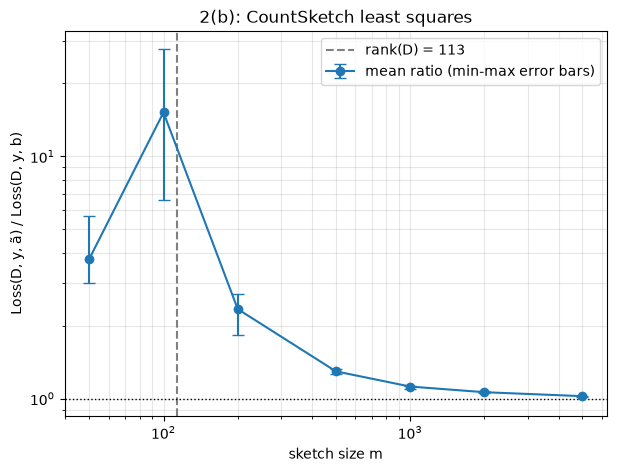

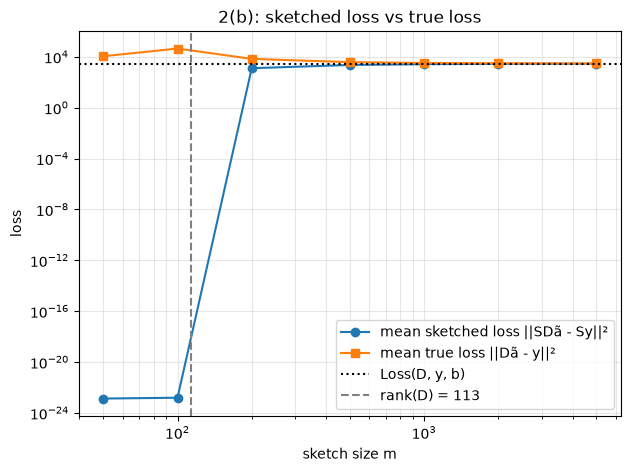

In [7]:
plt.figure(figsize=(7, 5))
plt.errorbar(summary.index, summary['mean_ratio'],
             yerr=[summary['mean_ratio'] - summary['min_ratio'],
                   summary['max_ratio'] - summary['mean_ratio']],
             fmt='o-', capsize=4, label='mean ratio (min-max error bars)')
plt.axvline(r, ls='--', c='gray', label=f'rank(D) = {r}')
plt.axhline(1, ls=':', c='k', lw=1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('sketch size m')
plt.ylabel('Loss(D, y, ã) / Loss(D, y, b)')
plt.title('2(b): CountSketch least squares')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

# Sketched loss vs true loss of a~
plt.figure(figsize=(7, 5))
plt.plot(summary.index, summary['mean_sketched_loss'], 'o-', label='mean sketched loss ||SDã - Sy||²')
plt.plot(summary.index, res.groupby('m')['Loss(D,y,a~)'].mean(), 's-', label='mean true loss ||Dã - y||²')
plt.axhline(loss_b, ls=':', c='k', label='Loss(D, y, b)')
plt.axvline(r, ls='--', c='gray', label=f'rank(D) = {r}')
plt.xscale('log')
plt.yscale('log')   # sketched loss is ~1e-23 (zero up to rounding) for m < rank(D)
plt.xlabel('sketch size m')
plt.ylabel('loss')
plt.title('2(b): sketched loss vs true loss')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

**Answer (b).** The table above lists $\text{Loss}(D,y,\tilde a)$, its ratio to $\text{Loss}(D,y,b)$ and the sketched loss $\|SD\tilde a - Sy\|_2^2$ for all 35 runs; the summary gives the mean, smallest and largest ratio for each $m$.

* **Below $\operatorname{rank}(D) = 113$ ($m = 50, 100$).** $SD$ has only $m$ rows, fewer than the 113 independent directions of $D$, so $SDa = Sy$ has infinitely many exact solutions. `lstsq` returns one of them (the minimum-norm one), and the sketched loss is $\approx 10^{-23}$, i.e. zero up to rounding. A zero sketched loss says nothing about the real fit: the true loss is 3–28 times the optimum (mean ratio 3.8 at $m=50$ and 15.2 at $m=100$). The ratio is worst at $m=100$, just below the rank: there the sketched system is nearly square, the exact-fit solution is badly conditioned, and its entries become very large, so it extrapolates poorly to the rows that were not fitted.
* **Above $\operatorname{rank}(D)$ ($m \ge 200$).** The sketched problem is a true overdetermined regression. The sketched loss becomes positive and grows towards $\text{Loss}(D,y,b) = 2949.8$ (1275 at $m=200$, 2289 at $m=500$, 2887 at $m=5000$), so it becomes a usable estimate of the optimal loss, and it always underestimates the true loss of $\tilde a$ because $\tilde a$ is fitted to the sketch. The ratio falls steadily towards 1: 2.34, 1.30, 1.12, 1.06, 1.02 for $m = 200, 500, 1000, 2000, 5000$. This matches the known behaviour of sketch-and-solve, $\text{ratio} - 1 \approx r/(m - r)$ with $r = \operatorname{rank}(D) = 113$: the formula gives 1.30, 0.29, 0.13, 0.06, 0.023 for $m = 200, \dots, 5000$, against observed 1.34, 0.30, 0.12, 0.06, 0.023. So the excess loss falls roughly like $1/m$ once $m \gg r$. The min–max spread also shrinks as $m$ grows.
* **No ratio is below 1,** as expected: $b$ minimises $\text{Loss}(D,y,\cdot)$ exactly, so no other vector, $\tilde a$ included, can have a smaller loss.

### Part (c): Time of the sketched solve vs the full solve

In [8]:
timing = res.groupby('m')['time (s)'].mean().to_frame('mean sketch+solve time (s)')
timing['full solve time (s)'] = t_full
timing['speed-up (full / sketch)'] = t_full / timing['mean sketch+solve time (s)']
timing

,mean sketch+solve time (s),full solve time (s),speed-up (full / sketch)
m,,,
50,1.15627,3.66188,3.16698
100,1.18754,3.66188,3.08358
200,1.16151,3.66188,3.1527
500,1.17912,3.66188,3.1056
1000,1.17461,3.66188,3.11753
2000,1.27986,3.66188,2.86116
5000,1.6935,3.66188,2.16231


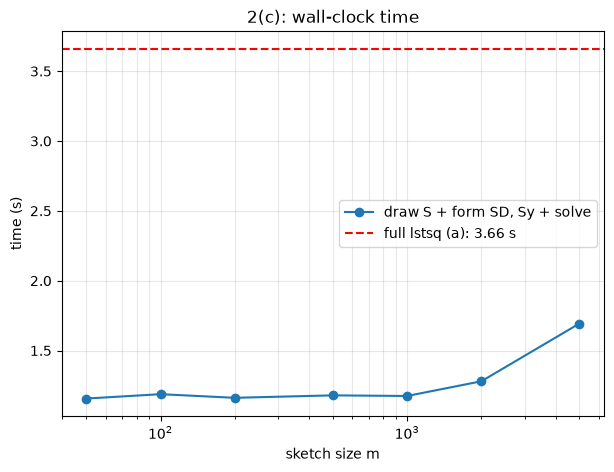

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(timing.index, timing['mean sketch+solve time (s)'], 'o-', label='draw S + form SD, Sy + solve')
plt.axhline(t_full, ls='--', c='r', label=f'full lstsq (a): {t_full:.2f} s')
plt.xscale('log')
plt.xlabel('sketch size m')
plt.ylabel('time (s)')
plt.title('2(c): wall-clock time')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

**Answer (c).** Drawing $S$, forming $SD$ and $Sy$ with `numpy.add.at`, and solving the $m \times 116$ problem takes about 1.2 s for $m \le 1000$, rising slightly to about 1.3–1.7 s at $m = 5000$, against about 3.7 s for the full solve in (a): roughly 2–3 times faster. The time depends only weakly on $m$, because almost all of it is spent forming $SD$: that is one pass over all $n \times d$ entries of $D$, whatever $m$ is. Solving the small sketched system costs only $O(m d^2)$, which is negligible even at $m = 5000$. So with CountSketch we get a 2–3× speed-up and, at $m = 5000$, a loss within about 2% of the optimum. (A faster scatter-add than `numpy.add.at` would make the sketch cheaper still.)

### Part (d): Norm preservation of the residual

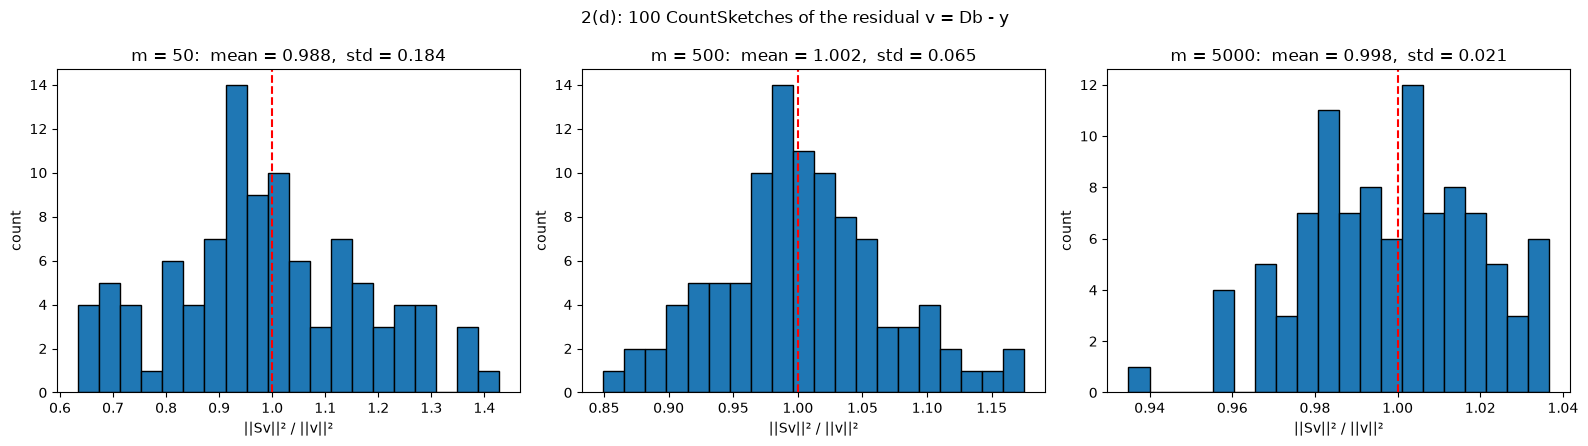

,mean,std,sqrt(2/m),min,max
m,,,,,
50,0.987864,0.183561,0.2,0.634262,1.42776
500,1.00243,0.0652957,0.0632456,0.849457,1.17518
5000,0.99822,0.0208378,0.02,0.934867,1.03672


In [10]:
v = D @ b - y
v_sq = v @ v

D_M_VALUES = [50, 500, 5000]
N_SKETCHES = 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
stats = []
for ax, m in zip(axes, D_M_VALUES):
    ratios = np.empty(N_SKETCHES)
    for t in range(N_SKETCHES):
        h, sigma = draw_countsketch(n, m, rng)
        Sv = apply_countsketch(h, sigma, m, v)
        ratios[t] = (Sv @ Sv) / v_sq
    stats.append({'m': m, 'mean': ratios.mean(), 'std': ratios.std(ddof=1),
                  'sqrt(2/m)': np.sqrt(2 / m), 'min': ratios.min(), 'max': ratios.max()})
    ax.hist(ratios, bins=20, edgecolor='k')
    ax.axvline(1, c='r', ls='--')
    ax.set_title(f'm = {m}:  mean = {ratios.mean():.3f},  std = {ratios.std(ddof=1):.3f}')
    ax.set_xlabel('||Sv||² / ||v||²')
    ax.set_ylabel('count')
plt.suptitle('2(d): 100 CountSketches of the residual v = Db - y')
plt.tight_layout()
plt.show()

pd.DataFrame(stats).set_index('m')

**Answer (d).** For 100 independent CountSketches of the residual $v = Db - y$:

| $m$ | mean of $\|Sv\|_2^2/\|v\|_2^2$ | std | $\sqrt{2/m}$ |
|---|---|---|---|
| 50 | 0.988 | 0.184 | 0.200 |
| 500 | 1.002 | 0.065 | 0.063 |
| 5000 | 0.998 | 0.021 | 0.020 |

The mean is close to 1 for every $m$: CountSketch preserves squared norms in expectation, $\mathbb E\|Sv\|^2 = \|v\|^2$, because the random signs make the cross terms average to zero. The spread shrinks as $m$ grows. The standard deviation falls by about $\sqrt{10} \approx 3.2$ each time $m$ grows 10-fold, and matches $\sqrt{2/m}$, the theoretical value for a vector whose mass is spread over many entries. At $m = 50$ a single sketch can be off by about 40% (range 0.63–1.43); at $m = 5000$ it stays within about 7% (range 0.93–1.04). This is the JL property of CountSketch that makes the sketched regression in (b) work.

### Part (e): CountSketch vs dense Gaussian sketch on a 50,000-row subset

In [11]:
N_SUB = 50_000
M_E = 500

# Fixed subset, chosen once with its own seed
sub_rng = np.random.default_rng(SEED)
idx = sub_rng.choice(n, size=N_SUB, replace=False)
D_sub, y_sub = D[idx], y[idx]

b_sub = np.linalg.lstsq(D_sub, y_sub, rcond=None)[0]
loss_b_sub = loss(D_sub, y_sub, b_sub)
print(f"Loss(D', y', b') = {loss_b_sub:.4f}")

rows_e = []
for rep in range(N_REPEATS):
    # (i) CountSketch
    t0 = time.perf_counter()
    h, sigma = draw_countsketch(N_SUB, M_E, rng)
    SD = apply_countsketch(h, sigma, M_E, D_sub)
    Sy = apply_countsketch(h, sigma, M_E, y_sub)
    t_cs = time.perf_counter() - t0
    a_cs = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    rows_e.append({'method': 'CountSketch', 'rep': rep + 1, 'sketch time (s)': t_cs,
                   'ratio': loss(D_sub, y_sub, a_cs) / loss_b_sub})

    # (ii) dense Gaussian S with N(0, 1/m) entries
    t0 = time.perf_counter()
    S = rng.normal(0.0, 1.0 / np.sqrt(M_E), size=(M_E, N_SUB))
    SD = S @ D_sub
    Sy = S @ y_sub
    t_g = time.perf_counter() - t0
    a_g = np.linalg.lstsq(SD, Sy, rcond=None)[0]
    rows_e.append({'method': 'Gaussian', 'rep': rep + 1, 'sketch time (s)': t_g,
                   'ratio': loss(D_sub, y_sub, a_g) / loss_b_sub})
    del S

res_e = pd.DataFrame(rows_e)
display(res_e)
res_e.groupby('method')[['sketch time (s)', 'ratio']].mean()

Loss(D', y', b') = 275.1544


,method,rep,sketch time (s),ratio
0,CountSketch,1,0.135312,1.25051
1,Gaussian,1,0.968371,1.24365
2,CountSketch,2,0.136748,1.23177
3,Gaussian,2,0.875147,1.25779
4,CountSketch,3,0.123843,1.30729
5,Gaussian,3,0.982031,1.26521
6,CountSketch,4,0.154591,1.30611
7,Gaussian,4,0.980583,1.23336
8,CountSketch,5,0.149609,1.29219
9,Gaussian,5,1.00172,1.31462


,sketch time (s),ratio
method,,
CountSketch,0.14002,1.27758
Gaussian,0.961571,1.26293


In [12]:
# Size of a dense Gaussian S for the full D at the largest m used in (b)
m_big = 5000
entries = m_big * n
print(f"Dense S for full D at m={m_big}: {entries:,} entries = "
      f"{entries * 8 / 1e9:.1f} GB in float64 ({entries * 4 / 1e9:.1f} GB in float32)")

Dense S for full D at m=5000: 2,470,105,000 entries = 19.8 GB in float64 (9.9 GB in float32)


**Answer (e).** On the fixed 50,000-row subset with $m = 500$, averaged over 5 repetitions:

| sketch | time to draw $S$ and form $SD'$, $Sy'$ | $\text{Loss}(D',y',\tilde a)/\text{Loss}(D',y',b')$ |
|---|---|---|
| CountSketch | ≈ 0.1 s | 1.278 |
| Gaussian $N(0, 1/m)$ | ≈ 0.7–1.0 s | 1.263 |

The two sketches are equally accurate: the difference in mean ratio (1.26 vs 1.28) is smaller than the spread between repetitions (1.23–1.31 for both). CountSketch was about 7 times faster here. It touches each entry of $D'$ once ($O(n d)$ work), while the Gaussian sketch has to generate $m \times n = 25$ million random numbers and compute a dense product ($O(m n d)$ work).

**On the full $D$ I would use CountSketch.** For the full data the gap grows with $m$: a dense $S$ at $m = 5000$ would have $5000 \times 494{,}021 \approx 2.5$ billion entries, about 20 GB in float64 (10 GB in float32). That is too large to hold in memory on most machines, and multiplying by it would take far longer than solving the full least-squares problem directly, which defeats the purpose of sketching. CountSketch needs only two length-$n$ arrays ($h$ and $\sigma$), costs one pass over $D$ whatever $m$ is, and gives the same accuracy.